# test_QR3qGate — Python port

Python/Jupyter port of Artyom M. Grigoryan's MATLAB code (March 29, 2025) that generates a 3-qubit (8×8) orthogonal gate from a 28-angle key through the DsiHT-based QR decomposition (not the fast path):



In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True, linewidth=120)
MATLAB_A2_TYPO = False      # True reproduces "A2=Q2*Q2" from test_QR3qGate.m

## Gate AND DsiHT 

In [ ]:


def gate_rotateH1U(u):
    c1, s1 = np.cos(u), np.sin(u)
    return np.array([[c1, -s1],
                     [s1,  c1]])
#cos -sin sin cos


def _rot8(p, q, u):
    # 8x8 identity with the rotation by u placed on rows/cols (p, q), 0-based
    #np.eye = diagonal 8 x 8 
    S = np.eye(8); c, s = np.cos(u), np.sin(u)
    S[p, p] = c; S[p, q] = -s
    S[q, p] = s; S[q, q] = c
    #S[p,p] , S[q,q] are in the diagonal
    return S


def _swap8(*pairs):
    # 8x8 permutation (cnoT) exchanging each listed pair (p, q), 0-based
    S = np.eye(8)
    for p, q in pairs:
        S[[p, q]] = S[[q, p]]
        #interchange p and q 
    return S

In [ ]:
# call: dsiht_8in8U.m — H(8;8): 8-in-8 DsiHT with 7 given angles U
# Artyom M. Grigoryan, EE UTSA, Oct.7, 2024
def dsiht_8in8U(U):
    # Stage 1
    S1 = _rot8(0, 1, U[0])   #1 -> (BP: 0,1)
    S2 = _rot8(2, 3, U[1])   #2 -> (BP: 2,3)
    S3 = _rot8(4, 5, U[2])   #3 -> (BP: 4,5)
    S4 = _rot8(6, 7, U[3])   #4 -> (BP: 6,7)
    A1 = S4 @ S3 @ S2 @ S1 #resulting matrix
    # Stage 2
    S5 = _rot8(0, 2, U[4])   #5 -> (BP: 0,2)
    S6 = _rot8(4, 6, U[5])   #6 -> (BP: 4,6)
    A2 = S6 @ S5 #resulting matrix
    # Stage 3
    S7 = _rot8(0, 4, U[6])   #7 -> (BP: 0,4)
    A3 = S7 #final resulting matrix

    Q = A3 @ A2 @ A1         # Q = S7*(S6*S5)*(S4*S3*S2*S1)
    
    print('8-8 DsiHT: seven rotations: S7*(S6*S5)*(S4*S3*S2*S1)')
    return Q, S1, S2, S3, S4, S5, S6, S7


# call: dsiht_7in8U.m — H(8;7): 7-in-8 DsiHT with 6 given angles U
# Artyom M. Grigoryan, EE UTSA, March 29, 2025
def dsiht_7in8U(U):
    # Stage 1
    S0 = _swap8((0, 1))      # CNOT (BP: 0,1)
    S1 = _rot8(2, 3, U[0])   # 1 (BP: 2,3)
    S2 = _rot8(4, 5, U[1])   # 2 (BP: 4,5)
    S3 = _rot8(6, 7, U[2])   # 3 (BP: 6,7)
    A1 = S3 @ S2 @ S1 @ S0
    # Stage 2
    S4 = _rot8(0, 2, U[3])   # 4 (BP: 0,2)
    S5 = _rot8(4, 6, U[4])   # 5 (BP: 4,6)
    A2 = S5 @ S4
    # Stage 3
    S6 = _rot8(0, 4, U[5])   # 6 (BP: 0,4)
    A3 = S0 @ S6
    Q = A3 @ A2 @ A1         # Q = (S0*S6)*(S5*S4)*S3*S2*S1*S0
    print('7-8 DsiHT: Six rotations, 2 CNOTs: (S0*S6)*(S5*S4)*S3*S2*S1*S0')
    return Q, S0, S1, S2, S3, S4, S5, S6


# call: dsiht_6in8U.m — H(8;6): 6-in-8 DsiHT with 5 angles, 1 CNOT
# Artyom M. Grigoryan, EE UTSA, Oct.6, 2024
def dsiht_6in8U(U):
    # Stage 1
    S1 = _rot8(2, 3, U[0])   # 1 (BP: 2,3)
    S2 = _rot8(4, 5, U[1])   # 2 (BP: 4,5)
    S3 = _rot8(6, 7, U[2])   # 3 (BP: 6,7)
    A1 = S3 @ S2 @ S1
    # Stage 2
    S4 = _rot8(4, 6, U[3])   # 4 (BP: 4,6)
    S0 = _swap8((4, 6))      # 5 CNOT (BP: 4,6)
    A2 = S0 @ S4
    # Stage 3
    S5 = _rot8(2, 6, U[4])   # 5 (BP: 2,6)
    A3 = S5
    Q = A3 @ A2 @ A1         # Q = S5*(S0*S4)*(S3*S2*S1)
    print('6-8 DsiHT: Five rotations, 1 CNOT: S5*(S0*S4)*(S3*S2*S1)')
    return Q, S1, S2, S3, S4, S0, S5


# call: dsiht_5in8U.m — H(8;5): 5-in-8 DsiHT with 4 angles U
# Artyom M. Grigoryan, EE UTSA, March 29, 2025
def dsiht_5in8U(U):
    # Stage 1
    S1 = _rot8(4, 5, U[0])           # 1 (BP: 4,5)
    S2 = _rot8(6, 7, U[1])           # 2 (BP: 6,7)
    S0 = _swap8((4, 5), (6, 7))      # Two CNOTs (BP 4,5 and 6,7)
    A1 = S0 @ S2 @ S1
    # Stage 2
    S3 = _rot8(5, 7, U[2])           # 3 (BP: 5,7)
    S02 = _swap8((5, 7))             # CNOT (BP: 5,7)
    A2 = S02 @ S3
    # Stage 3
    S4 = _rot8(3, 7, U[3])           # 5 (BP: 3,7)
    A3 = S4
    Q = A3 @ A2 @ A1                 # Q = S4*(S02*S3)*(S0*S2*S1)
    print('5-8 DsiHT: Four rotations and 3(2) CNOTs: S4*(S02*S3)*(S0*S2*S1)')
    return Q, S1, S2, S0, S3, S02, S4


# call: dsiht_4in8U.m — H(8;4): 4-in-8 DsiHT with 3 angles
# Artyom M. Grigoryan, EE UTSA, Oct.7, 2024
def dsiht_4in8U(U):
    # Stage 1
    S1 = _rot8(4, 5, U[0])   # 1 (BP: 4,5)
    S2 = _rot8(6, 7, U[1])   # 2 (BP: 6,7)
    A1 = S2 @ S1
    # Stage 2
    S3 = _rot8(4, 6, U[2])   # 3 (BP: 4,6)
    A2 = S3
    Q = A2 @ A1              # Q = S3*(S2*S1)
    print('4-8 DsiHT: Three rotations: S3*(S2*S1)')
    return Q, S1, S2, S3


# call: dsiht_3in8U.m — H(8;3): 3-in-8 DsiHT with 2 angles
# Artyom M. Grigoryan, EE UTSA, March 29, 2025
def dsiht_3in8U(U):
    # Stage 1
    S1 = _rot8(6, 7, U[0])   # 1 (BP: 6,7)
    S0 = _swap8((6, 7))      # CNOT
    A1 = S0 @ S1
    # Stage 2
    S2 = _rot8(5, 7, U[1])   # 3 (BP: 5,7)
    A2 = S2
    Q = A2 @ A1              # Q = S2*(S0*S1)
    print('3-8 DsiHT: Two rotations, 1 CNOT: S2*(S0*S1)')
    return Q, S1, S0, S2


# call: dsiht_2in8U.m — H(8;2): 2-in-8 DsiHT with 1 angle U
# Artyom M. Grigoryan, EE UTSA, Oct.7, 2024
def dsiht_2in8U(U):
    S1 = np.eye(8); S1[6:8, 6:8] = gate_rotateH1U(np.atleast_1d(U)[0])   # 1 (BP: 6,7)
    Q = S1
    print('2-8 DsiHT: One rotation: Q')
    return Q





In [9]:
# call: key_angles3Q.m — 28 random angles, uniform on [-pi, pi)
def key_angles3Q(rng=None):
    rng = np.random.default_rng() if rng is None else rng
    p2 = 2 * np.pi
    U1 = -np.pi + p2 * rng.random(7)
    U2 = -np.pi + p2 * rng.random(6)
    U3 = -np.pi + p2 * rng.random(5)
    U4 = -np.pi + p2 * rng.random(4)
    U5 = -np.pi + p2 * rng.random(3)
    U6 = -np.pi + p2 * rng.random(2)
    U7 = -np.pi + p2 * rng.random(1)
    return U1, U2, U3, U4, U5, U6, U7

QR-based generated 3 qubit transform: Seven Stages: 
8-8 DsiHT: seven rotations: S7*(S6*S5)*(S4*S3*S2*S1)
7-8 DsiHT: Six rotations, 2 CNOTs: (S0*S6)*(S5*S4)*S3*S2*S1*S0
6-8 DsiHT: Five rotations, 1 CNOT: S5*(S0*S4)*(S3*S2*S1)
5-8 DsiHT: Four rotations and 3(2) CNOTs: S4*(S02*S3)*(S0*S2*S1)
4-8 DsiHT: Three rotations: S3*(S2*S1)
3-8 DsiHT: Two rotations, 1 CNOT: S2*(S0*S1)
2-8 DsiHT: One rotation: Q

  Generated angles in degrees:
  #1 angles:  178.0048  -42.4765  117.7733  121.4119  171.2912 -152.1990  -65.7157
  #2 angles:  151.0399   63.3130  -77.1030  -39.7645  -97.1210 -119.8940
  #3 angles: -124.7629  170.6730  -27.3975 -157.2682   -3.0289
  #4 angles:  -76.1964 -103.8181 -105.3243   28.4474
  #5 angles:   32.7061  139.7032 -140.4601
  #6 angles:   -1.3312  -75.5524
  #7 angles:   -5.0935

 det(A)= -1.000000 

Ais =
 [[ 0.4063 -0.0121 -0.1103  0.134  -0.5724 -0.61    0.3238 -0.0109]
 [ 0.0142  0.3829 -0.3362 -0.3682  0.5394 -0.5498 -0.0447  0.0967]
 [-0.0459 -0.3125 -0.2529 -0.742

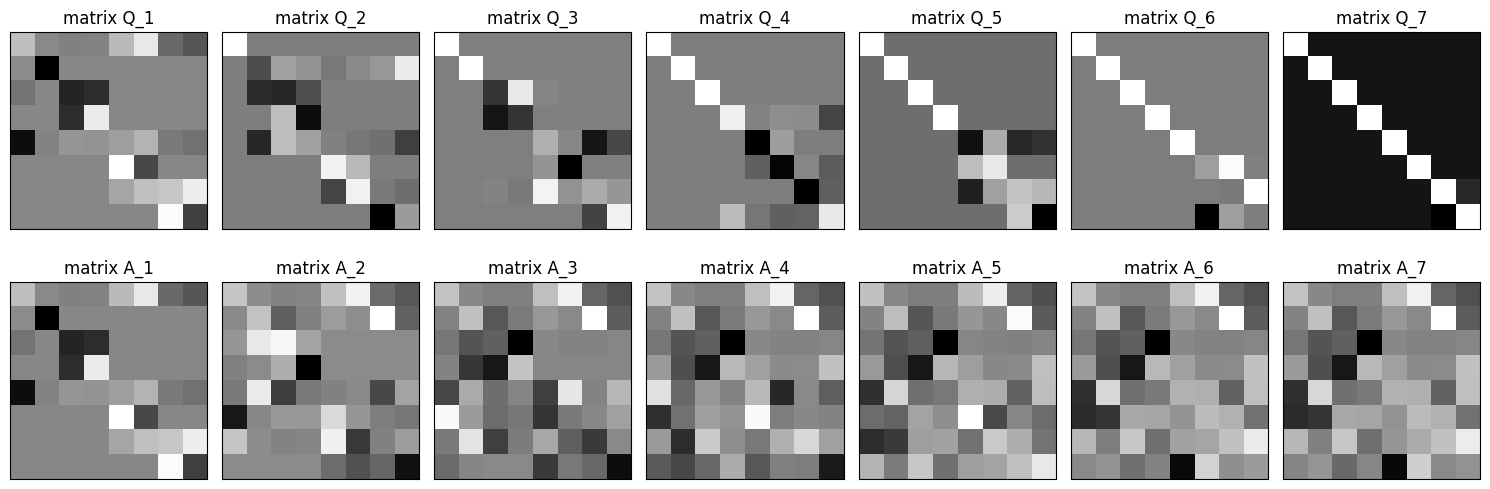

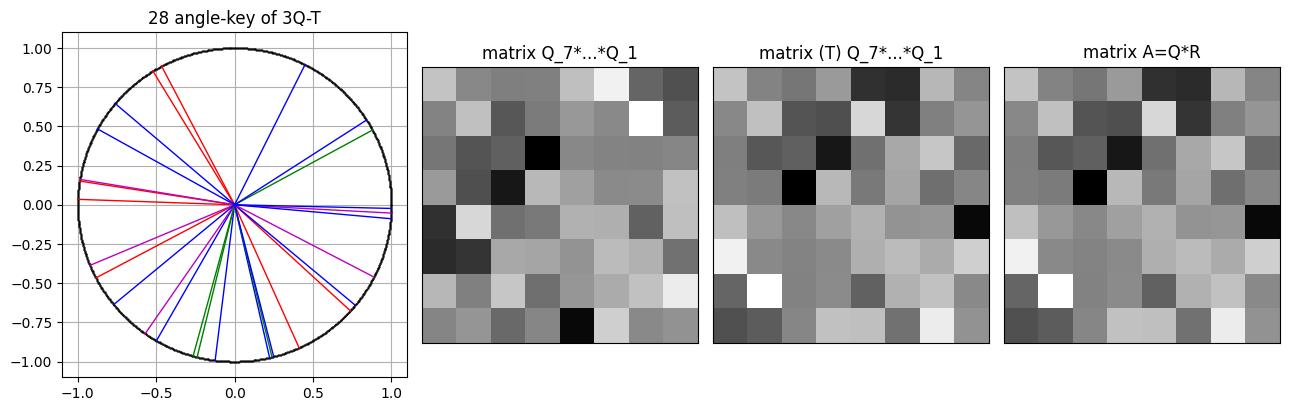

In [5]:
def test_QR3qGate(angles=None, r8=None, seed=None, plot=True):
    rng = np.random.default_rng(seed)
    print('QR-based generated 3 qubit transform: Seven Stages: ')
    U1, U2, U3, U4, U5, U6, U7 = key_angles3Q(rng) if angles is None else [np.atleast_1d(np.asarray(u, float)) for u in angles]
    a = 180 / np.pi

    Q1, S1, S2, S3, S4, S5, S6, S7 = dsiht_8in8U(U1)
    Q1 = S7 @ (S6 @ S5) @ (S4 @ S3 @ S2 @ S1)          # 1st matrix of the QR decomposition
    Q2 = dsiht_7in8U(U2)[0]                            # 2nd
    A2 = Q2 @ Q2 if MATLAB_A2_TYPO else Q2 @ Q1
    Q3 = dsiht_6in8U(U3)[0];  A3 = Q3 @ A2             # 3rd
    Q4 = dsiht_5in8U(U4)[0];  A4 = Q4 @ A3             # 4th
    Q5 = dsiht_4in8U(U5)[0];  A5 = Q5 @ A4             # 5th
    Q6 = dsiht_3in8U(U6)[0];  A6 = Q6 @ A5             # 6th
    Q7 = dsiht_2in8U(U7);     A7 = Q7 @ A6             # 7th

    # The unitary matrix in the QR-decomposition
    Q = Q7 @ Q6 @ Q5 @ Q4 @ Q3 @ Q2 @ Q1
    Qinv = Q1.T @ Q2.T @ Q3.T @ Q4.T @ Q5.T @ Q6.T @ Q7.T   # = Q', the matrix A for the circuit

    # Diagonal matrix diag{1,1,1,1,1,1,1, -1 or 1}
    R = np.eye(8)
    r8 = rng.random() if r8 is None else r8
    if r8 < 0.5:
        R[7, 7] = -1
    Ais = Q.T @ R                                      # QR decomposition

    print('\n  Generated angles in degrees:')
    for k, U in enumerate([U1, U2, U3, U4, U5, U6, U7], 1):
        print(f'  #{k} angles: ' + ' '.join(f'{v:9.4f}' for v in U * a))
    print(f'\n det(A)= {np.linalg.det(Ais):f} \n')
    print('Ais =\n', Ais)
    print('R =\n', R)
    print('End of calculation ')
    print('Ais*Ais\' =\n', Ais @ Ais.T)              # should be the identity matrix

    if plot:
        fig, ax = plt.subplots(2, 7, figsize=(15, 5.4))
        for k, (Qk, Ak) in enumerate(zip([Q1, Q2, Q3, Q4, Q5, Q6, Q7], [Q1, A2, A3, A4, A5, A6, A7]), 1):
            ax[0, k - 1].imshow(Qk, cmap='gray'); ax[0, k - 1].set_title(f'matrix Q_{k}')
            ax[1, k - 1].imshow(Ak, cmap='gray'); ax[1, k - 1].set_title(f'matrix A_{k}')
        for x in ax.ravel(): x.set_xticks([]); x.set_yticks([])
        plt.tight_layout(); plt.show()

        fig = plt.figure(figsize=(13, 4.4))
        g = fig.add_gridspec(1, 4, width_ratios=[1.25, 1, 1, 1])
        axc = fig.add_subplot(g[0])
        f = np.linspace(0, 2 * np.pi, 1024)
        axc.plot(np.cos(f), np.sin(f), '.', ms=1, color='k')
        for U, col in zip([U1, U2, U3, U4, U5, U6, U7], ['r', 'b', 'm', 'g', 'b', 'b', 'b']):   # colours as in MATLAB
            for af in U:
                axc.plot([0, np.cos(af)], [0, np.sin(af)], color=col, lw=1)
        axc.set_aspect('equal'); axc.grid(True); axc.set_title('28 angle-key of 3Q-T')
        for k, (M, t) in enumerate([(Q, 'matrix Q_7*...*Q_1'), (Q.T, "matrix (T) Q_7*...*Q_1"), (Ais, 'matrix A=Q*R')], 1):
            x = fig.add_subplot(g[k]); x.imshow(M, cmap='gray'); x.set_title(t); x.set_xticks([]); x.set_yticks([])
        plt.tight_layout(); plt.show()

    return dict(U=[U1, U2, U3, U4, U5, U6, U7], Q=[Q1, Q2, Q3, Q4, Q5, Q6, Q7], Qfull=Q, Qinv=Qinv, R=R, A=Ais)


out = test_QR3qGate(seed=2025)

In [6]:
Q, A, R = out['Qfull'], out['A'], out['R']
print('max |Q Q^T - I|   =', np.abs(Q @ Q.T - np.eye(8)).max())
print('max |A A^T - I|   =', np.abs(A @ A.T - np.eye(8)).max())
print('det(A)            =', round(np.linalg.det(A), 12), '   R(8,8) =', R[7, 7])
print('max |Qinv - Q^T|  =', np.abs(out['Qinv'] - Q.T).max())

# independent implementation: operations in application order (0-based rows)
STAGES = [
    [("rot", 0, 1, 0), ("rot", 2, 3, 1), ("rot", 4, 5, 2), ("rot", 6, 7, 3), ("rot", 0, 2, 4), ("rot", 4, 6, 5), ("rot", 0, 4, 6)],
    [("swap", 0, 1), ("rot", 2, 3, 0), ("rot", 4, 5, 1), ("rot", 6, 7, 2), ("rot", 0, 2, 3), ("rot", 4, 6, 4), ("rot", 0, 4, 5), ("swap", 0, 1)],
    [("rot", 2, 3, 0), ("rot", 4, 5, 1), ("rot", 6, 7, 2), ("rot", 4, 6, 3), ("swap", 4, 6), ("rot", 2, 6, 4)],
    [("rot", 4, 5, 0), ("rot", 6, 7, 1), ("swap", 4, 5), ("swap", 6, 7), ("rot", 5, 7, 2), ("swap", 5, 7), ("rot", 3, 7, 3)],
    [("rot", 4, 5, 0), ("rot", 6, 7, 1), ("rot", 4, 6, 2)],
    [("rot", 6, 7, 0), ("swap", 6, 7), ("rot", 5, 7, 1)],
    [("rot", 6, 7, 0)],
]
Qind = np.eye(8)
for st, U in zip(STAGES, out['U']):
    for op in st:
        Qind = (_swap8((op[1], op[2])) if op[0] == "swap" else _rot8(op[1], op[2], U[op[3]])) @ Qind
print('max |A - independent| =', np.abs(Qind.T @ R - A).max())

max |Q Q^T - I|   = 5.551115123125783e-16
max |A A^T - I|   = 3.3306690738754696e-16
det(A)            = -1.0    R(8,8) = 1.0
max |Qinv - Q^T|  = 2.220446049250313e-16
max |A - independent| = 3.3306690738754696e-16


In [ ]:
U1d = [ 10, -20,  30, -40,  50, -60,  70]
U2d = [ 15, -25,  35, -45,  55, -65]
U3d = [ 12, -22,  32, -42,  52]
U4d = [ 14, -24,  34, -44]
U5d = [ 16, -26,  36]
U6d = [ 18, -28]
U7d = [ 19]
R88 = -1          # R(8,8) in the MATLAB run

angles = [np.deg2rad(u) for u in [U1d, U2d, U3d, U4d, U5d, U6d, U7d]]
mat = test_QR3qGate(angles=angles, r8=0.0 if R88 < 0 else 1.0, plot=False)

QR-based generated 3 qubit transform: Seven Stages: 
8-8 DsiHT: seven rotations: S7*(S6*S5)*(S4*S3*S2*S1)
7-8 DsiHT: Six rotations, 2 CNOTs: (S0*S6)*(S5*S4)*S3*S2*S1*S0
6-8 DsiHT: Five rotations, 1 CNOT: S5*(S0*S4)*(S3*S2*S1)
5-8 DsiHT: Four rotations and 3(2) CNOTs: S4*(S02*S3)*(S0*S2*S1)
4-8 DsiHT: Three rotations: S3*(S2*S1)
3-8 DsiHT: Two rotations, 1 CNOT: S2*(S0*S1)
2-8 DsiHT: One rotation: Q

  Generated angles in degrees:
  #1 angles:   10.0000  -20.0000   30.0000  -40.0000   50.0000  -60.0000   70.0000
  #2 angles:   15.0000  -25.0000   35.0000  -45.0000   55.0000  -65.0000
  #3 angles:   12.0000  -22.0000   32.0000  -42.0000   52.0000
  #4 angles:   14.0000  -24.0000   34.0000  -44.0000
  #5 angles:   16.0000  -26.0000   36.0000
  #6 angles:   18.0000  -28.0000
  #7 angles:   19.0000

 det(A)= 1.000000 

Ais =
 [[ 0.2165  0.5499  0.3121  0.446  -0.1494  0.5391  0.0916  0.1817]
 [-0.0382  0.2065 -0.1341  0.3     0.0502 -0.1247  0.3394 -0.8454]
 [-0.2462 -0.1179  0.7848 -0.1006

In [8]:
try:
    from qiskit import QuantumCircuit, transpile
    from qiskit.circuit.library import RYGate, XGate, ZGate
    from qiskit.quantum_info import Operator
except ImportError:
    QuantumCircuit = None
    print('Qiskit not installed: pip install qiskit')

def _target_and_controls(p, q):
    t = (p ^ q).bit_length() - 1
    ctrls = [b for b in range(3) if b != t]
    state = sum(((p >> b) & 1) << k for k, b in enumerate(ctrls))
    return t, ctrls, state

def qr3q_circuit(U, R88):
    qc_Q = QuantumCircuit(3)
    for st, Uk in zip(STAGES, U):
        for op in st:
            t, ctrls, s = _target_and_controls(op[1], op[2])
            gate = XGate() if op[0] == "swap" else RYGate(2 * Uk[op[3]])
            qc_Q.append(gate.control(2, ctrl_state=s), ctrls + [t])
    qc = QuantumCircuit(3)
    if R88 < 0:
        qc.append(ZGate().control(2, ctrl_state=3), [0, 1, 2])
    return qc.compose(qc_Q.inverse())                  # A = Q^T R: R first, then Q^{-1}

if QuantumCircuit is not None:
    qc = qr3q_circuit(out['U'], out['R'][7, 7])
    print('max |circuit - A| =', np.abs(Operator(qc).data - out['A']).max())
    t = transpile(qc, basis_gates=['rz', 'sx', 'x', 'cx'], optimization_level=3, seed_transpiler=7)
    print('CNOTs:', t.count_ops().get('cx', 0), '  depth:', t.depth())

max |circuit - A| = 3.3306690738754696e-16
CNOTs: 262   depth: 698
